#### ***Agentic_AI Chatbot***

In [1]:
import warnings
warnings.filterwarnings("ignore")

from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Annotated
from langchain_core.messages import BaseMessage,HumanMessage
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph.message import add_messages

from dotenv import load_dotenv
load_dotenv()

True

In [2]:
# Define Our Model
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

In [3]:
# Define State 
class ChatState(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [4]:
# Define Node 
def chat_node(state:ChatState):
    # user query
    messages = state["messages"]
    # send to llm
    response = llm.invoke(messages)
    return {'messages':[response]}

In [5]:
checkpoint = MemorySaver()

graph = StateGraph(ChatState)

graph.add_node('chat_node',chat_node)

graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

chatbot = graph.compile(checkpointer=checkpoint)

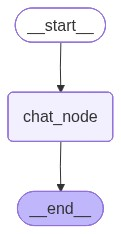

In [6]:
## Visualize Out Graph 
from IPython.display import Image
Image(chatbot.get_graph().draw_mermaid_png())

In [7]:
thread_id = "2"
initial_state = {
    'messages': [HumanMessage(content='What is my name?')]
}

config = {'configurable': {'thread_id': thread_id}}
response = chatbot.invoke(initial_state, config=config)

In [9]:
response['messages'][-1].content

'I don’t have any information about your name. If you’d like me to address you a certain way, just let me know!'

In [11]:
thread_id = "1"

while True:
    user_message = input('Type here: ')
    print('User:', user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        break

    config = {'configurable': {'thread_id': thread_id}}
    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config=config)
    print('AI:', response['messages'][-1].content)

User: Hello
AI: Hello! How can I help you today?
User: Myself Ankit
AI: Nice to meet you, Ankit! How can I assist you today?
User: What is my name
AI: Your name is Ankit.
User: ok tell me more about era of aiml engineer as fresher 
AI: ### The “Era” of an AI/ML Engineer (Fresh‑Grad Perspective)

The field of artificial intelligence and machine‑learning (AI/ML) is moving at a break‑neck pace. If you’re stepping in as a **fresh graduate**, you’re entering a landscape that’s both exciting and a little overwhelming. Below is a practical, high‑level guide that covers the **current state of the market**, the **core skill set** you’ll need, **how to get your first job**, and **what to expect in the next few years**.

---

## 1️⃣ Where the Industry Stands (2024‑2026)

| Trend | What It Means for Freshers |
|-------|----------------------------|
| **AI‑first products** (e.g., Copilot, ChatGPT, generative art tools) | Companies want engineers who can **integrate large‑scale models** into product